In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


In [2]:
df = pd.read_csv('/content/retail_sales_dataset.csv')
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
df.tail()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [5]:
df.shape

(1000, 9)

In [12]:
df['Transaction ID'].nunique()

1000

In [13]:
df['Transaction ID'].unique()

array([   1,    2,    3,    4,    5,    6,    7,    8,    9,   10,   11,
         12,   13,   14,   15,   16,   17,   18,   19,   20,   21,   22,
         23,   24,   25,   26,   27,   28,   29,   30,   31,   32,   33,
         34,   35,   36,   37,   38,   39,   40,   41,   42,   43,   44,
         45,   46,   47,   48,   49,   50,   51,   52,   53,   54,   55,
         56,   57,   58,   59,   60,   61,   62,   63,   64,   65,   66,
         67,   68,   69,   70,   71,   72,   73,   74,   75,   76,   77,
         78,   79,   80,   81,   82,   83,   84,   85,   86,   87,   88,
         89,   90,   91,   92,   93,   94,   95,   96,   97,   98,   99,
        100,  101,  102,  103,  104,  105,  106,  107,  108,  109,  110,
        111,  112,  113,  114,  115,  116,  117,  118,  119,  120,  121,
        122,  123,  124,  125,  126,  127,  128,  129,  130,  131,  132,
        133,  134,  135,  136,  137,  138,  139,  140,  141,  142,  143,
        144,  145,  146,  147,  148,  149,  150,  1

In [14]:
df['Date'].nunique()

345

In [15]:
df['Date'].unique()

array(['2023-11-24', '2023-02-27', '2023-01-13', '2023-05-21',
       '2023-05-06', '2023-04-25', '2023-03-13', '2023-02-22',
       '2023-12-13', '2023-10-07', '2023-02-14', '2023-10-30',
       '2023-08-05', '2023-01-17', '2023-01-16', '2023-02-17',
       '2023-04-22', '2023-04-30', '2023-09-16', '2023-11-05',
       '2023-01-14', '2023-10-15', '2023-04-12', '2023-11-29',
       '2023-12-26', '2023-08-03', '2023-04-23', '2023-08-18',
       '2023-10-29', '2023-05-23', '2023-01-04', '2023-03-23',
       '2023-12-24', '2023-06-24', '2023-03-21', '2023-04-21',
       '2023-06-22', '2023-07-14', '2023-02-19', '2023-07-03',
       '2023-06-26', '2023-11-06', '2023-05-16', '2023-01-23',
       '2023-08-24', '2023-10-02', '2023-03-05', '2023-07-13',
       '2023-02-10', '2023-10-10', '2023-05-31', '2023-11-18',
       '2023-11-13', '2023-07-05', '2023-10-23', '2023-04-09',
       '2023-12-27', '2023-02-05', '2023-01-24', '2023-12-05',
       '2023-04-27', '2023-05-29', '2023-02-21', '2023-

In [16]:
df['Customer ID'].nunique()

1000

In [17]:
df['Customer ID'].unique()

array(['CUST001', 'CUST002', 'CUST003', 'CUST004', 'CUST005', 'CUST006',
       'CUST007', 'CUST008', 'CUST009', 'CUST010', 'CUST011', 'CUST012',
       'CUST013', 'CUST014', 'CUST015', 'CUST016', 'CUST017', 'CUST018',
       'CUST019', 'CUST020', 'CUST021', 'CUST022', 'CUST023', 'CUST024',
       'CUST025', 'CUST026', 'CUST027', 'CUST028', 'CUST029', 'CUST030',
       'CUST031', 'CUST032', 'CUST033', 'CUST034', 'CUST035', 'CUST036',
       'CUST037', 'CUST038', 'CUST039', 'CUST040', 'CUST041', 'CUST042',
       'CUST043', 'CUST044', 'CUST045', 'CUST046', 'CUST047', 'CUST048',
       'CUST049', 'CUST050', 'CUST051', 'CUST052', 'CUST053', 'CUST054',
       'CUST055', 'CUST056', 'CUST057', 'CUST058', 'CUST059', 'CUST060',
       'CUST061', 'CUST062', 'CUST063', 'CUST064', 'CUST065', 'CUST066',
       'CUST067', 'CUST068', 'CUST069', 'CUST070', 'CUST071', 'CUST072',
       'CUST073', 'CUST074', 'CUST075', 'CUST076', 'CUST077', 'CUST078',
       'CUST079', 'CUST080', 'CUST081', 'CUST082', 

In [18]:
df['Gender'].nunique()

2

In [19]:
df['Gender'].unique()

array(['Male', 'Female'], dtype=object)

In [20]:
df['Product Category'].nunique()

3

In [21]:
df['Product Category'].unique()

array(['Beauty', 'Clothing', 'Electronics'], dtype=object)

In [22]:
df['Quantity'].nunique()

4

In [23]:
df['Quantity'].unique()

array([3, 2, 1, 4])

In [24]:
df['Age'].nunique()

47

In [25]:
df['Age'].unique()

array([34, 26, 50, 37, 30, 45, 46, 63, 52, 23, 35, 22, 64, 42, 19, 27, 47,
       62, 18, 49, 28, 38, 43, 39, 44, 51, 58, 48, 55, 20, 40, 54, 36, 31,
       21, 57, 25, 56, 29, 61, 32, 41, 59, 60, 33, 53, 24])

In [26]:
df['Price per Unit'].nunique()

5

In [27]:
df['Price per Unit'].unique()

array([ 50, 500,  30,  25, 300])

In [28]:
df['Total Amount'].nunique()

18

In [29]:
df['Total Amount'].unique()

array([ 150, 1000,   30,  500,  100,   50,  600,  200,   75, 1500,  120,
       2000,  900,  300, 1200,   90,   25,   60])

In [30]:
df.isnull().sum()

,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


In [31]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


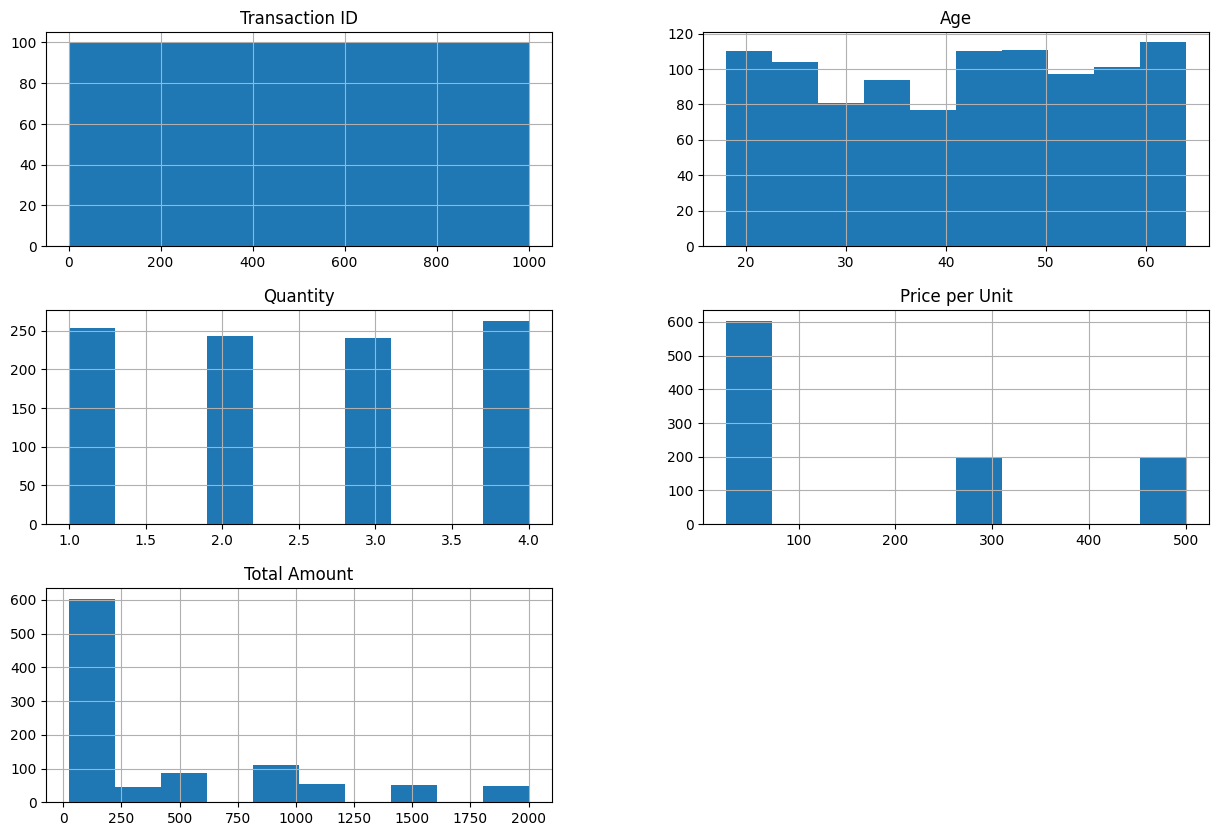

In [32]:
df.hist(figsize=(15,10))
plt.show()

In [33]:
df.sample(3)

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
113,114,2023-07-22,CUST114,Female,22,Beauty,4,25,100
317,318,2023-10-24,CUST318,Male,61,Clothing,1,25,25
207,208,2023-10-04,CUST208,Female,34,Electronics,4,50,200


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [35]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [36]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


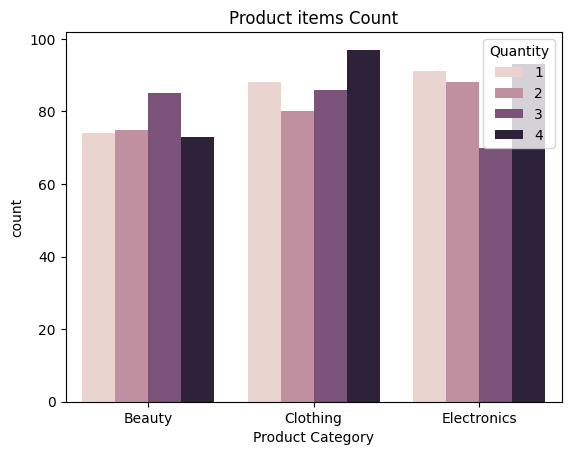

In [37]:
sns.countplot(x='Product Category' , hue='Quantity',data=df)
plt.title('Product items Count')
plt.show()

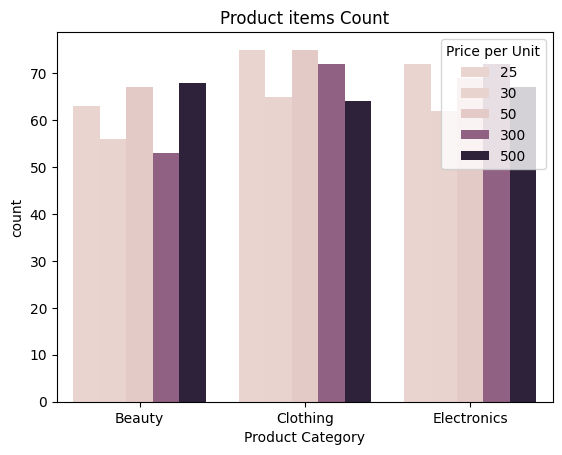

In [45]:
sns.countplot(x='Product Category' , hue='Price per Unit',data=df)
plt.title('Product items Count')
plt.show()

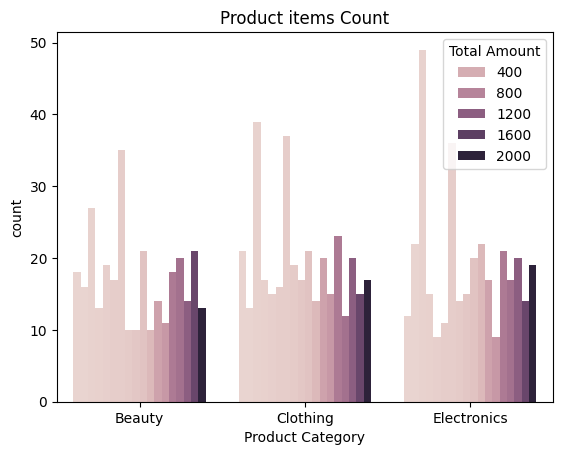

In [42]:
sns.countplot(x='Product Category' , hue='Total Amount',data=df)
plt.title('Product items Count')
plt.show()

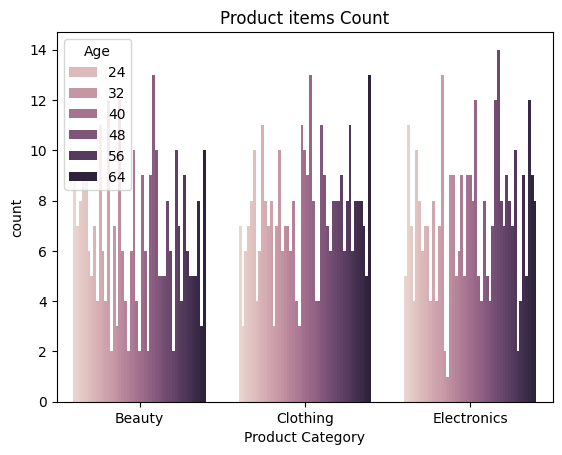

In [43]:
sns.countplot(x='Product Category' , hue='Age',data=df)
plt.title('Product items Count')
plt.show()

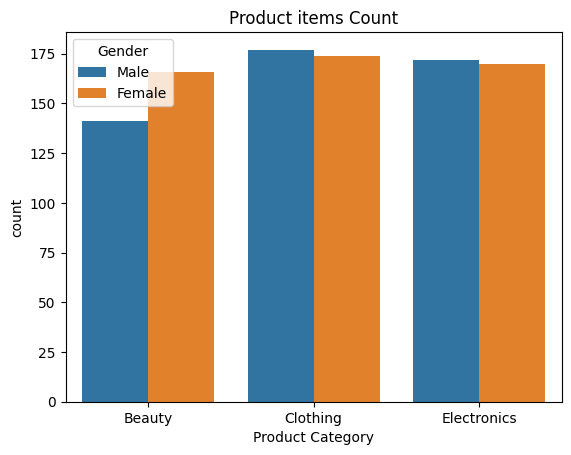

In [44]:
sns.countplot(x='Product Category' , hue='Gender',data=df)
plt.title('Product items Count')
plt.show()